In [1]:
!pip install transformers -q
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 73.8 MB/s eta 0:00:00


In [2]:
import re
import gensim
import csv
import nltk
import os
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from gensim.models import Word2Vec
from transformers import pipeline
from transformers import logging as transformers_logging
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, LSTM, Dropout, Bidirectional
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

transformers_logging.set_verbosity_error()

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [3]:
df_komen = pd.read_csv("comments.csv")
df_komen.head(25)

,comments
0,It was like a TV series
1,that maybe the best game we can enjoy in the w...
2,FINALLY THIS GAME COMING OUT THIS YEAR AFTER A...
3,Only 26mil views 😐 I guess most of the players...
4,this is so peak
5,Here for the 1OOth time.
6,69 days left
7,"Well, I&#39;ll watch it again"
8,Atleast it doesnt have special powers in. You ...
9,As soon as I saw the picture of the staff and ...


In [6]:
def preproses_text(text):
    text = html.unescape(text) # perbaiki cureg
    text = text.replace("’", "'").replace("‘", "'")
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\b\d{1,2}:\d{2}(?::\d{2})?\b', ' ', text) # timestamp
    text = re.sub(r'@[A-Za-z0-9_]+', ' ', text)
    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def return_sentence(words):
  sentences = ' '.join(word for word in words)
  return sentences

# LABELLING ROBERTA
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
sentiment_classifier = pipeline('sentiment-analysis',
                                model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                                tokenizer="cardiffnlp/twitter-roberta-base-sentiment-latest")

def labelling_komen(text):
  hasil = sentiment_classifier(
      text,
      batch_size = 600,
      truncation = True,
      max_length = 510
      )

  sentimen = [result["label"].lower() for result in hasil]
  confidence = [result["score"] for result in hasil]
  return sentimen, confidence

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [17]:
df_komen['comments_cleaning'] = df_komen['comments'].apply(preproses_text)
df_komen['final_comments'] = df_komen['comments_cleaning'].apply(return_sentence)
df_komen = df_komen[df_komen['final_comments'] != ''].reset_index(drop=True)
df_komen['sentimen'], df_komen['confidence'] = labelling_komen(df_komen['final_comments'].tolist())
df_komen.head(25)

,comments,comments_cleaning,final_comments,sentimen,confidence
0,It was like a TV series,it was like a tv series,i t w a s l i k e a t v s e r i e s,neutral,0.776347
1,that maybe the best game we can enjoy in the w...,that maybe the best game we can enjoy in the w...,t h a t m a y b e t h e b e s t g a m ...,neutral,0.777874
2,FINALLY THIS GAME COMING OUT THIS YEAR AFTER A...,finally this game coming out this year after a...,f i n a l l y t h i s g a m e c o m i n ...,positive,0.829434
3,Only 26mil views 😐 I guess most of the players...,only 26mil views 😐 i guess most of the players...,o n l y 2 6 m i l v i e w s 😐 i g u ...,neutral,0.800376
4,this is so peak,this is so peak,t h i s i s s o p e a k,neutral,0.767640
5,Here for the 1OOth time.,here for the 1ooth time.,h e r e f o r t h e 1 o o t h t i m e .,neutral,0.807286
6,69 days left,69 days left,6 9 d a y s l e f t,neutral,0.865057
7,"Well, I&#39;ll watch it again","well, i'll watch it again","w e l l , i ' l l w a t c h i t a g a i n",neutral,0.773575
8,Atleast it doesnt have special powers in. You ...,atleast it doesnt have special powers in. you ...,a t l e a s t i t d o e s n t h a v e ...,neutral,0.833981
9,As soon as I saw the picture of the staff and ...,as soon as i saw the picture of the staff and ...,a s s o o n a s i s a w t h e p i ...,neutral,0.839949


Pelatihan dengan ekstrasi fitur menggunakan Continuous Bag of Words (CBoW) dan Skip-Gram. Split data latih dan data tes dengan perbandingan 80 : 20.

In [18]:
text = df_komen['final_comments']
sentimen = df_komen['sentimen']

labeling = LabelEncoder()
label_sentimen = labeling.fit_transform(sentimen)

x_train, x_test, y_train, y_test = train_test_split(text, label_sentimen,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=label_sentimen)

text_token = [doc.split() for doc in x_train]
cbow = gensim.models.Word2Vec(
    text_token,
    window=5,
    min_count=1,
    vector_size = 100
)

sgm = gensim.models.Word2Vec(
    text_token,
    window=5,
    min_count=1,
    vector_size = 100,
    sg=1
)

vocab_size = 10000
max_len = 100
e_dim = 100
token = Tokenizer(num_words = vocab_size, oov_token = '<OOV>')
token.fit_on_texts(x_train)

word_index = token.word_index

x_train_seq = token.texts_to_sequences(x_train)
x_test_seq = token.texts_to_sequences(x_test)

x_train = pad_sequences(x_train_seq,
                        maxlen=max_len,
                        padding='post',
                        truncating='post')
x_test = pad_sequences(x_test_seq,
                       maxlen=max_len,
                       padding='post',
                       truncating='post')

def vector_matrix(model, index, size, dim):
  matrix = np.zeros((size, dim))
  for word, i in index.items():
    if i < size:
      if word in model.wv:
        matrix[i] = model.wv[word]

  return matrix

cbow_matrix = vector_matrix(cbow, word_index, vocab_size, e_dim)
sgm_matrix = vector_matrix(sgm, word_index, vocab_size, e_dim)

Pelatihan dengan LSTM

In [22]:
model_cbow = Sequential([
    Embedding(input_dim = vocab_size,
              output_dim = 100,
              input_length = max_len,
              weights=[cbow_matrix],
              trainable=True),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])
opt_cbow = tf.keras.optimizers.Adam(learning_rate=0.001)
model_cbow.compile(optimizer = opt_cbow,
                   loss = 'sparse_categorical_crossentropy',
                   metrics = ['accuracy'])
history_cbow = model_cbow.fit(x_train, y_train,
                              validation_split = 0.1,
                              epochs = 15,
                              batch_size = 64,
                              verbose = 1)

loss_cbow, accuracy_cbow = model_cbow.evaluate(x_test, y_test)

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


339/339 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9206 - loss: 0.3040 - val_accuracy: 0.9384 - val_loss: 0.1796
Epoch 2/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9427 - loss: 0.1745 - val_accuracy: 0.9513 - val_loss: 0.1482
Epoch 3/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9566 - loss: 0.1234 - val_accuracy: 0.9642 - val_loss: 0.1067
Epoch 4/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9639 - loss: 0.1007 - val_accuracy: 0.9746 - val_loss: 0.0829
Epoch 5/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9705 - loss: 0.0869 - val_accuracy: 0.9734 - val_loss: 0.0883
Epoch 6/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9723 - loss: 0.0803 - val_accuracy: 0.9780 - val_loss: 0.0828
Epoch 7/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9751 - loss: 0.0723 - val_accuracy: 0.9734 - val_loss: 0.0819
Epoch 8/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9767 - loss: 0.0666 - val_accuracy: 0.9759 - va

In [23]:
model_sgm = Sequential([
    Embedding(input_dim = vocab_size,
              output_dim = 100,
              input_length = max_len,
              weights=[sgm_matrix],
              trainable=True),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])
opt_sgm = tf.keras.optimizers.Adam(learning_rate=0.001)
model_sgm.compile(optimizer = opt_sgm,
                   loss = 'sparse_categorical_crossentropy',
                   metrics = ['accuracy'])
history_sgm = model_sgm.fit(x_train, y_train,
                             validation_split = 0.1,
                             epochs = 15,
                             batch_size = 64,
                             verbose = 1)

loss_sgm, accuracy_sgm = model_sgm.evaluate(x_test, y_test)

Epoch 1/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9173 - loss: 0.3322 - val_accuracy: 0.9172 - val_loss: 0.3114
Epoch 2/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9336 - loss: 0.2308 - val_accuracy: 0.9609 - val_loss: 0.1310
Epoch 3/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9575 - loss: 0.1276 - val_accuracy: 0.9626 - val_loss: 0.1034
Epoch 4/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9656 - loss: 0.1006 - val_accuracy: 0.9767 - val_loss: 0.0888
Epoch 5/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9715 - loss: 0.0847 - val_accuracy: 0.9767 - val_loss: 0.0771
Epoch 6/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9729 - loss: 0.0795 - val_accuracy: 0.9742 - val_loss: 0.0815
Epoch 7/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9761 - loss: 0.0722 - val_accuracy: 0.9734 - val_loss: 0.0784
Epoch 8/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9761 - loss: 0.0689 - val_accuracy

Pelatihan dengan BiLSTM

In [24]:
model_cbow2 = Sequential([
    Embedding(input_dim = vocab_size,
              output_dim = 100,
              input_length = max_len,
              weights=[cbow_matrix],
              trainable=True),
    Bidirectional(LSTM(64)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])
opt_cbow2 = tf.keras.optimizers.Adam(learning_rate=0.001)
model_cbow2.compile(optimizer = opt_cbow2,
                   loss = 'sparse_categorical_crossentropy',
                   metrics = ['accuracy'])
history_cbow2 = model_cbow2.fit(x_train, y_train,
                              validation_split = 0.1,
                              epochs = 15,
                              batch_size = 64,
                              verbose = 1)

loss_cbow2, accuracy_cbow2 = model_cbow2.evaluate(x_test, y_test)

Epoch 1/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9211 - loss: 0.2772 - val_accuracy: 0.9334 - val_loss: 0.1845
Epoch 2/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9558 - loss: 0.1304 - val_accuracy: 0.9659 - val_loss: 0.0995
Epoch 3/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9690 - loss: 0.0923 - val_accuracy: 0.9742 - val_loss: 0.0778
Epoch 4/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9728 - loss: 0.0768 - val_accuracy: 0.9792 - val_loss: 0.0735
Epoch 5/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9769 - loss: 0.0669 - val_accuracy: 0.9780 - val_loss: 0.0726
Epoch 6/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9782 - loss: 0.0640 - val_accuracy: 0.9804 - val_loss: 0.0648
Epoch 7/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9800 - loss: 0.0569 - val_accuracy: 0.9750 - val_loss: 0.0726
Epoch 8/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9798 - loss: 0.0565 - val_accu

In [25]:
model_sgm2 = Sequential([
    Embedding(input_dim = vocab_size,
              output_dim = 100,
              input_length = max_len,
              weights=[sgm_matrix],
              trainable=True),
    Bidirectional(LSTM(64)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])
opt_sgm2 = tf.keras.optimizers.Adam(learning_rate=0.001)
model_sgm2.compile(optimizer = opt_sgm2,
                   loss = 'sparse_categorical_crossentropy',
                   metrics = ['accuracy'])
history_sgm2 = model_sgm2.fit(x_train, y_train,
                             validation_split = 0.1,
                             epochs = 15,
                             batch_size = 64,
                             verbose = 1)

loss_sgm2, accuracy_sgm2 = model_sgm2.evaluate(x_test, y_test)

Epoch 1/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9294 - loss: 0.2562 - val_accuracy: 0.9547 - val_loss: 0.1520
Epoch 2/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9593 - loss: 0.1204 - val_accuracy: 0.9659 - val_loss: 0.0952
Epoch 3/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9677 - loss: 0.0930 - val_accuracy: 0.9746 - val_loss: 0.0792
Epoch 4/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9755 - loss: 0.0740 - val_accuracy: 0.9771 - val_loss: 0.0726
Epoch 5/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9746 - loss: 0.0742 - val_accuracy: 0.9771 - val_loss: 0.0691
Epoch 6/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9777 - loss: 0.0635 - val_accuracy: 0.9767 - val_loss: 0.0720
Epoch 7/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9783 - loss: 0.0618 - val_accuracy: 0.9763 - val_loss: 0.0677
Epoch 8/15
339/339 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9799 - loss: 0.0580 - val_accu

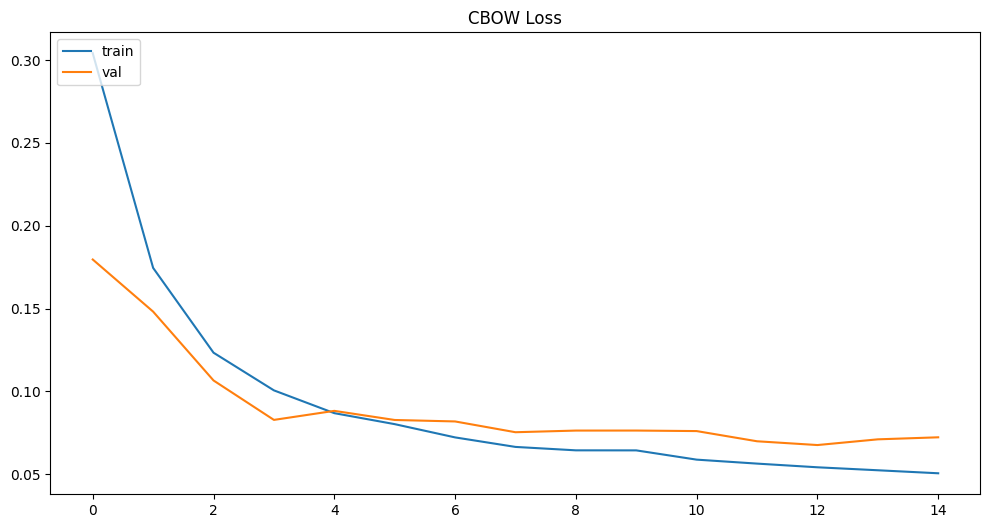

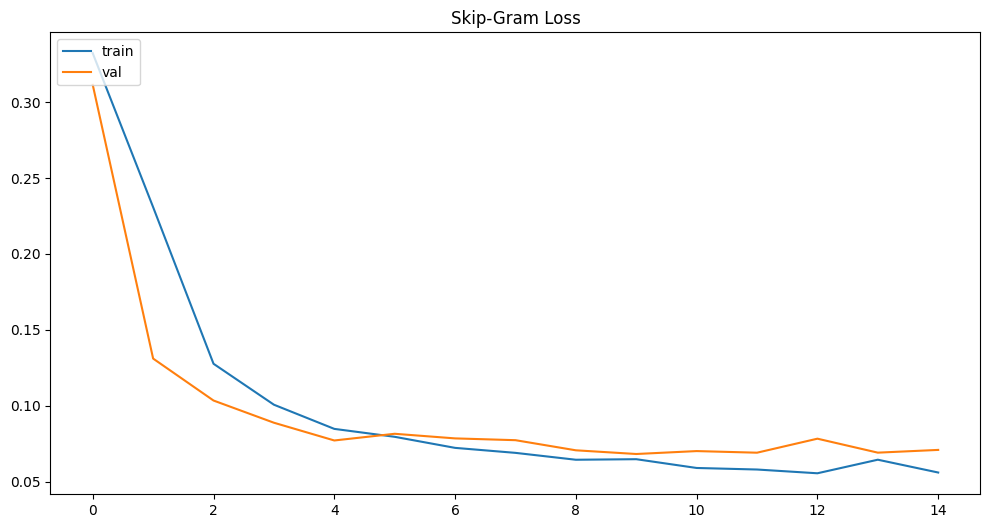

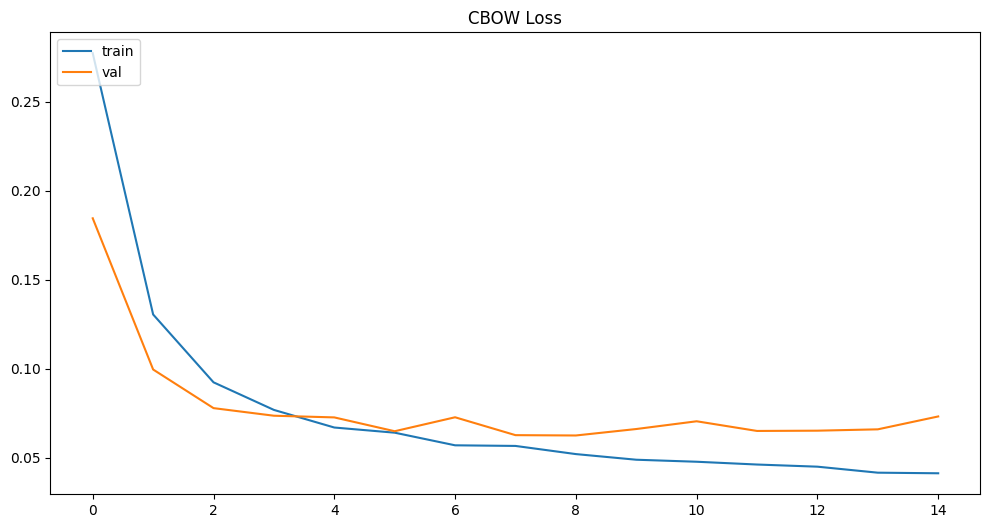

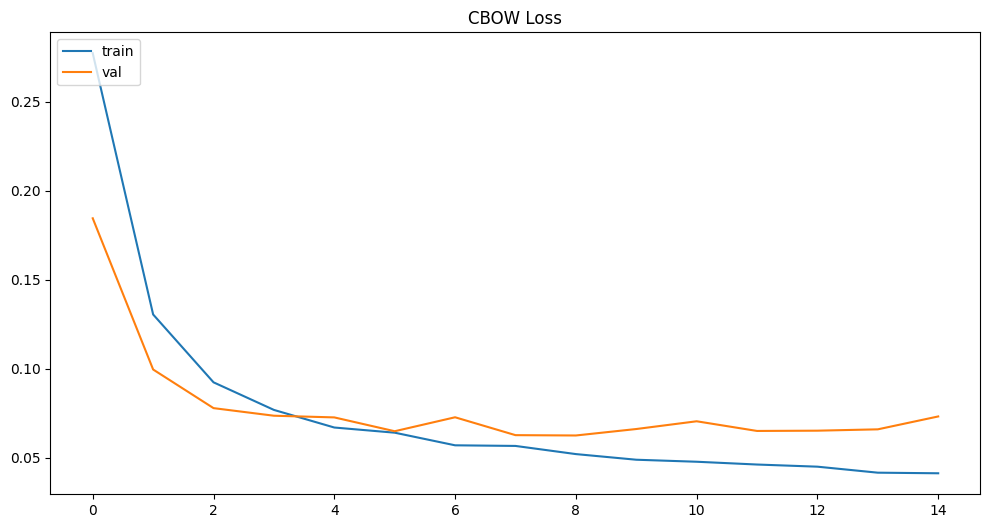


CBOW + LSTM Test Accuracy: 97.60%

Skip-Gram + LSTM Test Accuracy: 97.57%

CBoW + BiLSTM Test Accuracy: 97.45%

Skip-Gram + BiLSTM Test Accuracy: 97.69%


In [26]:
# CBOW + LSTM
plt.figure(figsize=(12, 6))
plt.plot(history_cbow.history['loss'])
plt.plot(history_cbow.history['val_loss'])
plt.title('CBOW Loss')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

# Skip-Gram + LSTM
plt.figure(figsize=(12, 6))
plt.plot(history_sgm.history['loss'])
plt.plot(history_sgm.history['val_loss'])
plt.title('Skip-Gram Loss')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

# CBOW + BILSTM
plt.figure(figsize=(12, 6))
plt.plot(history_cbow2.history['loss'])
plt.plot(history_cbow2.history['val_loss'])
plt.title('CBOW Loss')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

# CBOW + BILSTM
plt.figure(figsize=(12, 6))
plt.plot(history_cbow2.history['loss'])
plt.plot(history_cbow2.history['val_loss'])
plt.title('CBOW Loss')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

print(f"\nCBOW + LSTM Test Accuracy: {accuracy_cbow * 100:.2f}%")
print(f"\nSkip-Gram + LSTM Test Accuracy: {accuracy_sgm * 100:.2f}%")
print(f"\nCBoW + BiLSTM Test Accuracy: {accuracy_cbow2 * 100:.2f}%")
print(f"\nSkip-Gram + BiLSTM Test Accuracy: {accuracy_sgm2 * 100:.2f}%")

Pengetesan prediksi sentimen dari kalimat baru pada salah satu kombinasi pelatihan.

In [37]:
text_baru = input("Masukkan Teks: ")
text_baru = preproses_text(text_baru)
text_baru = token.texts_to_sequences([text_baru])
text_baru_seq = pad_sequences(text_baru, maxlen=max_len, padding='post', truncating='post')

prediksi = model_sgm2.predict(text_baru_seq, verbose=0)

indeks_kelas = np.argmax(prediksi, axis=1)
label_prediksi = labeling.inverse_transform(indeks_kelas)[0]
skor_confidence = np.max(prediksi)

print(f"Prediksi: {label_prediksi}")

Masukkan Teks: i'm gonna love this game
Prediksi: positive
